#Deep Learning para visión de computadoras
##Lab 3.2 — DCGAN: implementación, estabilidad y diagnóstico
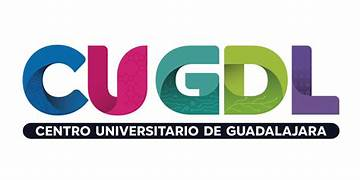

## Librerías

In [ ]:
import os, time, math, copy, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision
from torchvision import datasets
from torchvision.utils import make_grid
from scipy import linalg
from IPython.display import display
warnings.filterwarnings("ignore")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch", torch.__version__, "| dispositivo:", DEVICE,
      "(" + torch.cuda.get_device_name(0) + ")" if DEVICE.type == "cuda" else "← activa la GPU: Entorno de ejecución → Cambiar tipo de entorno → T4")

def fijar_semilla(s=0):
    torch.manual_seed(s); np.random.seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)

def mostrar_grid(x, titulo="", nrow=10, tam=(8, 8)):
    """x en [-1, 1], forma (N, C, H, W)."""
    g = make_grid(x.detach().cpu()[: nrow * nrow], nrow=nrow, normalize=True, value_range=(-1, 1), pad_value=1)
    plt.figure(figsize=tam); plt.imshow(g.permute(1, 2, 0).numpy(), cmap="gray"); plt.axis("off"); plt.title(titulo); plt.show()

PyTorch 2.11.0+cu130 | dispositivo: cuda (Tesla T4)


In [ ]:
NOMBRES_CLASES = {
    "FashionMNIST": ["camiseta", "pantalón", "suéter", "vestido", "abrigo", "sandalia", "camisa", "tenis", "bolsa", "botín"],
    "MNIST": [str(i) for i in range(10)],
    "CIFAR10": ["avión", "auto", "pájaro", "gato", "venado", "perro", "rana", "caballo", "barco", "camión"],
}

def cargar_tensor(nombre="FashionMNIST", split="train"):
    clase = getattr(datasets, nombre)
    ds = clase("datos", train=(split == "train"), download=True)
    x = torch.as_tensor(np.asarray(ds.data))
    y = torch.as_tensor(np.asarray(ds.targets)).long()
    if x.ndim == 3:                          # escala de grises 28x28 → (N, 1, 32, 32) con relleno de 2 px
        x = F.pad(x.unsqueeze(1), (2, 2, 2, 2))
    else:                                    # CIFAR10 viene como (N, 32, 32, 3)
        x = x.permute(0, 3, 1, 2)
    x = x.float().div(255).mul(2).sub(1)    # [0, 255] → [-1, 1] (coincide con la tanh del generador)
    return x.to(DEVICE), y.to(DEVICE)

def lotes(x, y, batch, mezclar=True):
    idx = torch.randperm(len(x), device=x.device) if mezclar else torch.arange(len(x), device=x.device)
    for i in range(0, len(x) - batch + 1, batch):   # se descarta el último lote incompleto (BN lo agradece)
        j = idx[i:i + batch]
        yield x[j], y[j]

### Configuración
Adaptable "FashionMNIST" | "MNIST" | "CIFAR10"

In [ ]:
CFG_BASE = dict(
    nombre="base",
    dataset="FashionMNIST",   # "FashionMNIST" | "MNIST" | "CIFAR10"
    nz=100, ngf=64, ndf=64,   # tamaño del ruido y anchura de G y D
    epocas=10, batch=128,
    lr_G=2e-4, lr_D=2e-4, beta1=0.5,      # valores del artículo DCGAN
    bn=True,                  # BatchNorm en G y D
    init_dcgan=True,          # pesos ~ N(0, 0.02)
    suavizado=0.9,            # one-sided label smoothing: etiqueta "real" = 0.9 (1.0 = sin suavizado)
    ruido_instancia=0.0,      # σ inicial de ruido gaussiano añadido a las entradas de D (decae a 0)
    pasos_D=1,                # actualizaciones de D por cada actualización de G
    semilla=0,
)

## Parte A

Cargamos **todo** el dataset en la GPU como un tensor de forma `(N, C, 32, 32)` con valores en **[−1, 1]** (rango de la `tanh` del generador). Las imágenes de 28×28 se rellenan con 2 píxeles para llegar a 32×32.

100%|██████████| 26.4M/26.4M [00:02<00:00, 10.0MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 173kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.19MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 8.98MB/s]


Entrenamiento (60000, 1, 32, 32) · prueba (10000, 1, 32, 32) · rango [-1.0, 1.0]


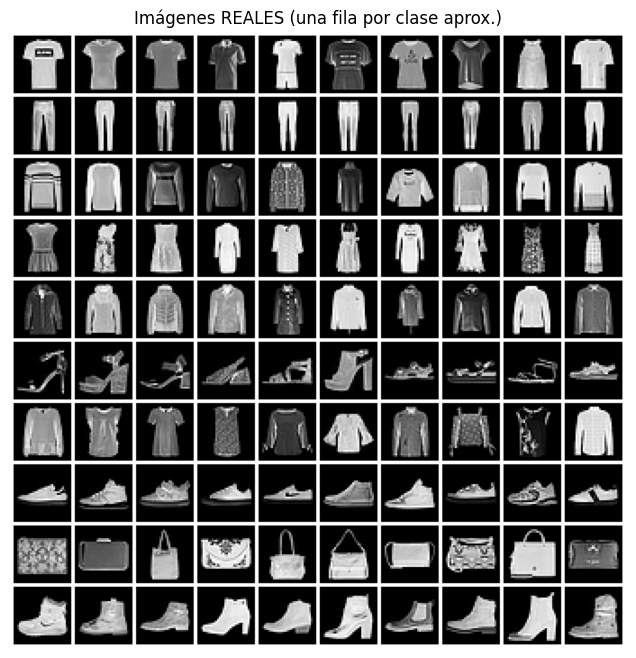

In [ ]:
X_tr, Y_tr = cargar_tensor(CFG_BASE["dataset"], "train")
X_te, Y_te = cargar_tensor(CFG_BASE["dataset"], "test")
CANALES = X_tr.shape[1]
CLASES = NOMBRES_CLASES[CFG_BASE["dataset"]]
print(f"Entrenamiento {tuple(X_tr.shape)} · prueba {tuple(X_te.shape)} · rango [{X_tr.min():.1f}, {X_tr.max():.1f}]")
mostrar_grid(X_tr[torch.argsort(Y_tr)[::600]][:100], "Imágenes REALES (una fila por clase aprox.)")

## Parte B Arquitectura DCGAN para 32×32

Es la arquitectura del tutorial de [Pythorch](https://docs.pytorch.org/tutorials/beginner/dcgan_faces_tutorial.html) con **una capa menos** (32×32 en lugar de 64×64).

Responde: ¿Cual es la diferencia entre la arquitectura GAN del articulo (2014) y DCGAN?
Agrega el diagrama de la arquitectura en el notebook

### Diferencias entre GAN (2014) y DCGAN (2015)

La arquitectura original de las **Generative Adversarial Networks (GAN)** propuesta por Ian Goodfellow en 2014 y las **Deep Convolutional GANs (DCGAN)** propuestas por Radford, Metz y Chintala a finales de 2015 marcan dos etapas cruciales en el desarrollo del aprendizaje generativo:

1. **Estructura de las Capas (Fully Connected vs. Convolutional):**
   * **GAN (2014):** Utilizaba principalmente capas densamente conectadas (Multilayer Perceptrons - MLP) tanto para el generador como para el discriminador
   * **DCGAN (2015):** Reemplaza las capas densas por **convoluciones espaciales** sin pooling

2. **Uso de Normalización por Lotes (Batch Normalization):**
   * **GAN (2014):** No incluía técnicas de normalización avanzadas, lo que dificultaba críticamente el flujo de gradientes en redes profundas.
   * **DCGAN (2015):** Introduce **Batch Normalization** tanto en el Generador como en el Discriminador para estabilizar el entrenamiento

3. **Funciones de Activación:**
   * **GAN (2014):** Utilizaba funciones como Maxout o activaciones tradicionales
   * **DCGAN (2015):** Propone un estándar riguroso:
     * En el **Generador**: se usa `ReLU` en todas las capas ocultas y `Tanh` en la capa de salida.
     * En el **Discriminador**: se utiliza `LeakyReLU` para todas las capas intermedias, evitando las "neuronas muertas" asociadas a gradientes nulos.

4. **Eliminación de Capas Completamente Conectadas (Pooling/Global Pooling):**
   * **DCGAN** elimina por completo las capas de Max-Pooling y las capas lineales densas en la parte superior de las redes de convolución, permitiendo que la red aprenda su propio submuestreo y minimice el recuento de parámetros redundantes.

### Diagrama de la Arquitectura DCGAN (Generador)

![DCGAN Generator Diagram](https://pytorch.org/tutorials/_images/dcgan_generator.png)

In [ ]:
def _bn(n, usar):            # BatchNorm
    return nn.BatchNorm2d(n) if usar else nn.Identity()

class Generador(nn.Module):
    """DCGAN para 32x32: z (nz) → 4x4 → 8x8 → 16x16 → 32x32. Sin capas densas, solo convoluciones transpuestas."""
    def __init__(self, nz=100, ngf=64, canales=1, bn=True):
        super().__init__()
        b = not bn            # si hay BN el sesgo es redundante
        self.red = nn.Sequential(
            # Entrada de tamaño (nz) x 1 x 1
            nn.ConvTranspose2d(nz, ngf * 4, kernel_size=4, stride=1, padding=0, bias=b),
            _bn(ngf * 4, bn),
            nn.ReLU(True),
            # Estado actual: (ngf*4) x 4 x 4
            nn.ConvTranspose2d(ngf * 4, ngf * 2, kernel_size=4, stride=2, padding=1, bias=b),
            _bn(ngf * 2, bn),
            nn.ReLU(True),
            # Estado actual: (ngf*2) x 8 x 8
            nn.ConvTranspose2d(ngf * 2, ngf, kernel_size=4, stride=2, padding=1, bias=b),
            _bn(ngf, bn),
            nn.ReLU(True),
            # Estado actual: (ngf) x 16 x 16
            nn.ConvTranspose2d(ngf, canales, kernel_size=4, stride=2, padding=1, bias=True),
            nn.Tanh()
            # Salida final: (canales) x 32 x 32
        )
    def forward(self, z):
        return self.red(z.view(z.size(0), -1, 1, 1))

class Discriminador(nn.Module):
    """Espejo del generador: convoluciones con stride 2 en lugar de pooling, LeakyReLU, y un LOGIT final.
    No ponemos Sigmoid: usamos BCEWithLogitsLoss, que es numéricamente estable."""
    def __init__(self, ndf=64, canales=1, bn=True):
        super().__init__()
        b = not bn
        self.red = nn.Sequential(
            # Entrada de tamaño (canales) x 32 x 32
            nn.Conv2d(canales, ndf, kernel_size=4, stride=2, padding=1, bias=True),
            nn.LeakyReLU(0.2, inplace=True),
            # Estado actual: (ndf) x 16 x 16
            nn.Conv2d(ndf, ndf * 2, kernel_size=4, stride=2, padding=1, bias=b),
            _bn(ndf * 2, bn),
            nn.LeakyReLU(0.2, inplace=True),
            # Estado actual: (ndf*2) x 8 x 8
            nn.Conv2d(ndf * 2, ndf * 4, kernel_size=4, stride=2, padding=1, bias=b),
            _bn(ndf * 4, bn),
            nn.LeakyReLU(0.2, inplace=True),
            # Estado actual: (ndf*4) x 4 x 4
            nn.Conv2d(ndf * 4, 1, kernel_size=4, stride=1, padding=0, bias=True)
            # Salida de tamaño: 1 x 1 x 1
        )
    def forward(self, x):
        return self.red(x).view(-1)

def init_dcgan(m):
    """Inicialización del artículo DCGAN (Radford et al., 2016): pesos ~ N(0, 0.02); BN: γ ~ N(1, 0.02), β = 0."""
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d, nn.Linear)):
        nn.init.normal_(m.weight, 0.0, 0.02)
        if m.bias is not None: nn.init.zeros_(m.bias)
    elif isinstance(m, nn.BatchNorm2d):
        nn.init.normal_(m.weight, 1.0, 0.02); nn.init.zeros_(m.bias)

def contar_parametros(m):
    return sum(p.numel() for p in m.parameters())

´Por cierto, el codigo de arriba lo complete medeinta la documentacion que viene en el link de la parte B´

In [ ]:
G_demo = Generador(CFG_BASE["nz"], CFG_BASE["ngf"], CANALES).to(DEVICE)
D_demo = Discriminador(CFG_BASE["ndf"], CANALES).to(DEVICE)
print(G_demo, "\n", D_demo)
print(f"\nParámetros: G = {contar_parametros(G_demo):,} · D = {contar_parametros(D_demo):,}")

x = torch.randn(4, CFG_BASE["nz"], device=DEVICE)
print("\nRecorrido de formas del generador:")
h = x.view(4, -1, 1, 1)
for capa in G_demo.red:
    h = capa(h)
    if isinstance(capa, nn.ConvTranspose2d): print(f"  {capa.__class__.__name__:<16s} → {tuple(h.shape)}")
print("Salida de D (logits):", D_demo(h).shape)

Generador(
  (red): Sequential(
    (0): ConvTranspose2d(100, 256, kernel_size=(4, 4), stride=(1, 1), bias=False)
    (1): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (4): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (7): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (8): ReLU(inplace=True)
    (9): ConvTranspose2d(64, 1, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (10): Tanh()
  )
) 
 Discriminador(
  (red): Sequential(
    (0): Conv2d(1, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): LeakyReLU(negative_slope=0.2, inplace=True)
    (2): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding

## Parte C evaluador externo

Entrenamos una CNN pequeña con **imágenes reales** (3 épocas, ≈ 91 % de exactitud en FashionMNIST). Nunca ve imágenes generadas durante su entrenamiento. Luego la usamos para medir:

| Métrica | Cómo se calcula | Qué detecta |
|---|---|---|
| **Cobertura** | Nº de clases que reciben ≥ 2 % de las muestras generadas (de 10) | Colapso de modo **entre** clases |
| **Entropía** | Entropía de la distribución de clases predichas (máx. ln 10 ≈ 2.30) | Desbalance / colapso parcial |
| **Confianza** | Probabilidad máxima promedio que el juez asigna | Muestras ambiguas o "manchas" |
| **[FID](https://torchmetrics.readthedocs.io/en/v0.8.0/image/frechet_inception_distance.html) de dominio** | Distancia de Fréchet entre características (128-d) de reales y generadas | Calidad **y** diversidad a la vez  |

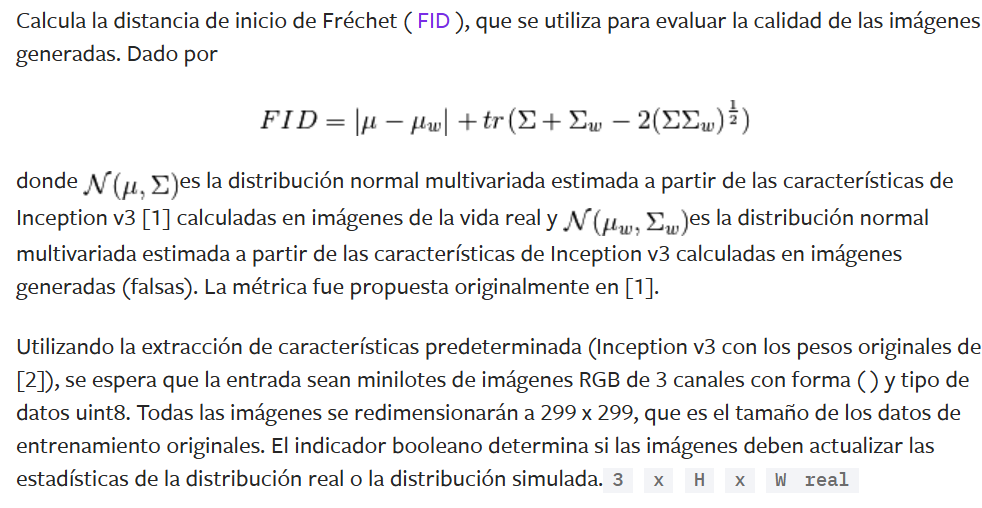

¿Cuales son las ventajas sobre la inspección visual? Explicalo con un ejemplo


La inspección visual (mirar las imágenes generadas) es un método intuitivo y primario para evaluar GANs, pero sufre de limitaciones severas como la **subjetividad**, el **sesgo de confirmación** y la **incapacidad de escala**.

---

### Ejemplo Práctico: El dilema del "Generador Monotemático"

Imagina que entrenamos una GAN con el dataset **FashionMNIST**:
* **Inspección Visual:** El usuario mira una rejilla de 64 imágenes generadas. Todas se ven increíblemente nítidas, detalladas y realistas: son calzados deportivos (*tenis*) y botas de excelente calidad.
* **El problema oculto:** El generador ha colapsado a solo producir calzado porque aprendió que es la forma más fácil de engañar al discriminador. Ha dejado de producir vestidos, camisetas, abrigos y bolsos por completo.
* **Cómo lo resuelven las métricas (segun google):**
  * El **ojo humano** calificaría la salida como "Excelente calidad (10/10)" basándose en la apariencia individual.
  * El **Juez** de evaluación nos arrojaría números fríos:
    * **Cobertura:** `2 / 10` clases (Alerta inmediata de colapso de modo).
    * **Entropía:** `0.69` (muy por debajo del óptimo de `2.30` para 10 clases uniformes).
    * **FID-dominio:** Muy elevado, porque la distribución de las características dista mucho de la distribución balanceada de prueba.

In [ ]:
class Juez(nn.Module):
    """CNN pequeña entrenada con datos REALES. Nos sirve de 'evaluador externo' de las imágenes generadas:
    (1) qué clase cree que es cada muestra → cobertura de modos; (2) sus características de 128-d → FID de dominio."""
    def __init__(self, canales=1, n_clases=10):
        super().__init__()
        self.cuerpo = nn.Sequential(
            nn.Conv2d(canales, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),   # 16
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),        # 8
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(), nn.AdaptiveAvgPool2d(1),
            nn.Flatten())
        self.cabeza = nn.Linear(128, n_clases)
    def forward(self, x): return self.cabeza(self.cuerpo(x))
    @torch.no_grad()
    def caracteristicas(self, x, lote=500):
        self.eval(); return torch.cat([self.cuerpo(x[i:i + lote]) for i in range(0, len(x), lote)])
    @torch.no_grad()
    def probabilidades(self, x, lote=500):
        self.eval(); return torch.cat([F.softmax(self(x[i:i + lote]), 1) for i in range(0, len(x), lote)])

def entrenar_juez(x, y, x_te, y_te, epocas=3, batch=256, aumento=False, semilla=0, verbose=True):
    fijar_semilla(semilla)
    m = Juez(x.shape[1], int(y.max()) + 1).to(DEVICE)
    opt = torch.optim.Adam(m.parameters(), 1e-3)
    for ep in range(epocas):
        m.train()
        for xb, yb in lotes(x, y, min(batch, len(x))):
            if aumento:   # aumento "clásico": desplazamientos aleatorios de ±2 px y espejo horizontal
                xb = torch.roll(xb, shifts=(int(np.random.randint(-2, 3)), int(np.random.randint(-2, 3))), dims=(2, 3))
                if np.random.rand() < 0.5: xb = xb.flip(3)
            loss = F.cross_entropy(m(xb), yb)
            opt.zero_grad(); loss.backward(); opt.step()
    acc = (m.probabilidades(x_te).argmax(1) == y_te).float().mean().item()
    if verbose: print(f"Juez: exactitud en prueba real = {acc:.3f}")
    return m, acc

In [ ]:
def estadisticos(feats):
    f = feats.double().cpu().numpy()
    return f.mean(0), np.cov(f, rowvar=False)

def distancia_frechet(mu1, s1, mu2, s2):
    """FID = ||μ1 − μ2||² + Tr(Σ1 + Σ2 − 2 (Σ1 Σ2)^{1/2})   (Heusel et al., 2017)"""
    diff = mu1 - mu2
    covmean = linalg.sqrtm(s1 @ s2)
    if not np.isfinite(covmean).all():          # estabilización numérica recomendada en la implementación oficial
        eps = np.eye(len(s1)) * 1e-6
        covmean = linalg.sqrtm((s1 + eps) @ (s2 + eps))
    covmean = np.real(covmean)
    return float(diff @ diff + np.trace(s1) + np.trace(s2) - 2 * np.trace(covmean))

def fid_dominio(juez, x_a, x_b):
    return distancia_frechet(*estadisticos(juez.caracteristicas(x_a)), *estadisticos(juez.caracteristicas(x_b)))

In [ ]:
JUEZ_RUTA = f"juez_{CFG_BASE['dataset']}.pt"
juez, acc_juez = entrenar_juez(X_tr, Y_tr, X_te, Y_te, epocas=3)
torch.save(juez.state_dict(), JUEZ_RUTA)

@torch.no_grad()
def metricas_generador(G, nz, n=2000, cond=None):
    """Métricas del juez sobre n muestras de G. 'cond' = etiquetas (solo para la cGAN del 5 de noviembre)."""
    G.eval()
    z = torch.randn(n, nz, device=DEVICE)
    xg = torch.cat([G(z[i:i + 500]) if cond is None else G(z[i:i + 500], cond[i:i + 500]) for i in range(0, n, 500)])
    G.train()
    p = juez.probabilidades(xg)
    frecuencia = torch.bincount(p.argmax(1), minlength=p.shape[1]).float() / n
    entropia = max(0.0, -(frecuencia * torch.log(frecuencia + 1e-12)).sum().item())
    return dict(cobertura=int((frecuencia >= 0.02).sum()), entropia=round(entropia, 3),
                confianza=round(p.max(1).values.mean().item(), 3),
                fid_dominio=round(fid_dominio(juez, X_te[:n], xg), 2)), xg, frecuencia.cpu()

print("Referencia — FID de dominio entre dos mitades de imágenes REALES:",
      round(fid_dominio(juez, X_te[:2000], X_tr[:2000]), 2))

Juez: exactitud en prueba real = 0.775
Referencia — FID de dominio entre dos mitades de imágenes REALES: 0.11


## Parte D Entrenamiento con registro completo

1. **Pérdida no saturante** para G y `BCEWithLogitsLoss` (estable numéricamente).
2. **Interruptores de estabilización** controlados desde `CFG`: *label smoothing*, ruido de instancia, BatchNorm, inicialización y pasos de D.
3. **Registro de todo**: pérdidas, $D(x)$, $D(G(z))$ antes y después de actualizar D, normas de los gradientes de G y D por iteración; métricas del juez y una rejilla con **ruido fijo** por época.

**Cómo leer las salidas de D** (tutorial de PyTorch): al inicio $D(x) \to 1$ y $D(G(z)) \to 0$; conforme G mejora, ambos deberían acercarse a 0.5 y oscilar alrededor de ese valor.

In [ ]:
def norma_gradiente(modelo):
    return torch.sqrt(sum((p.grad.detach() ** 2).sum() for p in modelo.parameters() if p.grad is not None)).item()

def entrenar_dcgan(cfg, verbose=True):
    fijar_semilla(cfg["semilla"])
    G = Generador(cfg["nz"], cfg["ngf"], CANALES, bn=cfg["bn"]).to(DEVICE)
    D = Discriminador(cfg["ndf"], CANALES, bn=cfg["bn"]).to(DEVICE)
    if cfg["init_dcgan"]:
        G.apply(init_dcgan); D.apply(init_dcgan)
    opt_G = torch.optim.Adam(G.parameters(), lr=cfg["lr_G"], betas=(cfg["beta1"], 0.999))
    opt_D = torch.optim.Adam(D.parameters(), lr=cfg["lr_D"], betas=(cfg["beta1"], 0.999))
    bce = nn.BCEWithLogitsLoss()
    z_fijo = torch.randn(100, cfg["nz"], device=DEVICE)          # mismo ruido en todas las épocas
    it_por_epoca = len(X_tr) // cfg["batch"]; total_it = cfg["epocas"] * it_por_epoca
    registro, por_epoca, rejillas = [], [], []
    it, t0, estado = 0, time.time(), "completado"
    for ep in range(cfg["epocas"]):
        for xr, _ in lotes(X_tr, Y_tr, cfg["batch"]):
            b = xr.size(0)
            sigma = cfg["ruido_instancia"] * max(0.0, 1 - it / total_it)      # el ruido decae linealmente
            ruido = (lambda t: t + sigma * torch.randn_like(t)) if sigma > 0 else (lambda t: t)
            # ---------- (1) Discriminador: maximizar log D(x) + log(1 − D(G(z))) ----------
            for _ in range(cfg["pasos_D"]):
                with torch.no_grad():
                    xf = G(torch.randn(b, cfg["nz"], device=DEVICE))
                out_r, out_f = D(ruido(xr)), D(ruido(xf))
                loss_D = bce(out_r, torch.full_like(out_r, cfg["suavizado"])) + bce(out_f, torch.zeros_like(out_f))
                opt_D.zero_grad(); loss_D.backward(); gD = norma_gradiente(D); opt_D.step()
            # ---------- (2) Generador: pérdida no saturante, minimizar −log D(G(z)) ----------
            xf = G(torch.randn(b, cfg["nz"], device=DEVICE))
            out_g = D(ruido(xf))
            loss_G = bce(out_g, torch.ones_like(out_g))
            opt_G.zero_grad(); loss_G.backward(); gG = norma_gradiente(G); opt_G.step()

            registro.append(dict(it=it, epoca=ep, loss_D=loss_D.item(), loss_G=loss_G.item(),
                                 D_x=torch.sigmoid(out_r).mean().item(), D_Gz_antes=torch.sigmoid(out_f).mean().item(),
                                 D_Gz_despues=torch.sigmoid(out_g).mean().item(), grad_D=gD, grad_G=gG))
            if not (math.isfinite(loss_D.item()) and math.isfinite(loss_G.item())):
                estado = f"DIVERGENCIA (NaN/inf) en la iteración {it}"; break
            it += 1
        if estado != "completado": break
        with torch.no_grad():
            G.eval(); rejillas.append(G(z_fijo).cpu()); G.train()
        met, _, frec = metricas_generador(G, cfg["nz"])
        por_epoca.append(dict(epoca=ep + 1, **met, frecuencias=frec.numpy().round(3)))
        if verbose:
            r = pd.DataFrame(registro[-it_por_epoca:]).mean()
            print(f"[{cfg['nombre']}] ép {ep + 1:>2}/{cfg['epocas']}  loss_D {r.loss_D:.3f}  loss_G {r.loss_G:.3f}  "
                  f"D(x) {r.D_x:.2f}  D(G(z)) {r.D_Gz_antes:.2f}→{r.D_Gz_despues:.2f}  | cobertura {met['cobertura']}/10  "
                  f"entropía {met['entropia']:.2f}  confianza {met['confianza']:.2f}  FID-d {met['fid_dominio']:.1f}  ({time.time() - t0:.0f} s)")
    return dict(cfg=cfg, G=G, D=D, registro=pd.DataFrame(registro), por_epoca=pd.DataFrame(por_epoca),
                rejillas=rejillas, estado=estado, segundos=round(time.time() - t0, 1))

base = entrenar_dcgan(CFG_BASE)
print("Estado:", base["estado"])

[base] ép  1/10  loss_D 0.576  loss_G 3.554  D(x) 0.79  D(G(z)) 0.11→0.06  | cobertura 3/10  entropía 1.11  confianza 0.67  FID-d 20.8  (23 s)
[base] ép  2/10  loss_D 0.713  loss_G 2.570  D(x) 0.73  D(G(z)) 0.17→0.13  | cobertura 8/10  entropía 1.73  confianza 0.72  FID-d 4.5  (46 s)
[base] ép  3/10  loss_D 0.794  loss_G 2.161  D(x) 0.69  D(G(z)) 0.21→0.17  | cobertura 8/10  entropía 1.87  confianza 0.72  FID-d 3.0  (70 s)
[base] ép  4/10  loss_D 0.822  loss_G 2.016  D(x) 0.68  D(G(z)) 0.22→0.19  | cobertura 8/10  entropía 2.01  confianza 0.73  FID-d 2.1  (95 s)
[base] ép  5/10  loss_D 0.844  loss_G 1.951  D(x) 0.67  D(G(z)) 0.23→0.20  | cobertura 8/10  entropía 1.98  confianza 0.75  FID-d 1.2  (121 s)
[base] ép  6/10  loss_D 0.837  loss_G 1.899  D(x) 0.67  D(G(z)) 0.23→0.20  | cobertura 8/10  entropía 2.02  confianza 0.77  FID-d 1.2  (146 s)
[base] ép  7/10  loss_D 0.851  loss_G 1.877  D(x) 0.67  D(G(z)) 0.23→0.21  | cobertura 9/10  entropía 2.07  confianza 0.77  FID-d 0.8  (171 s)
[b

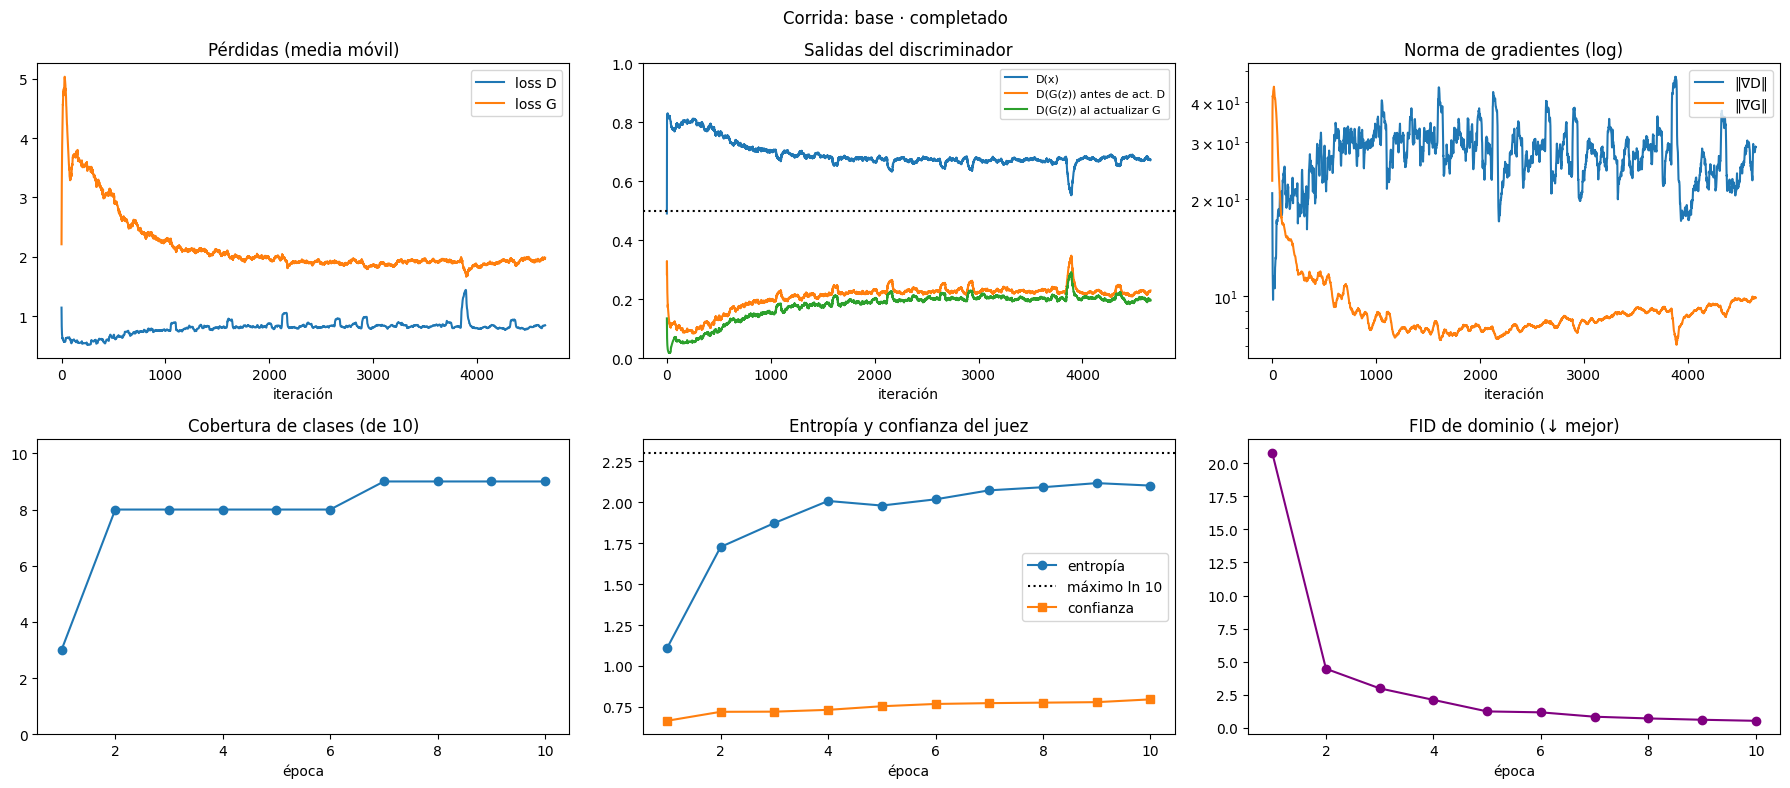

In [ ]:
def graficar_corrida(res, suavizar=50):
    r = res["registro"].rolling(suavizar, min_periods=1).mean(); e = res["por_epoca"]
    fig, ax = plt.subplots(2, 3, figsize=(18, 8))
    ax[0, 0].plot(r.it, r.loss_D, label="loss D"); ax[0, 0].plot(r.it, r.loss_G, label="loss G"); ax[0, 0].set_title("Pérdidas (media móvil)"); ax[0, 0].legend()
    ax[0, 1].plot(r.it, r.D_x, label="D(x)"); ax[0, 1].plot(r.it, r.D_Gz_antes, label="D(G(z)) antes de act. D"); ax[0, 1].plot(r.it, r.D_Gz_despues, label="D(G(z)) al actualizar G")
    ax[0, 1].axhline(0.5, c="k", ls=":"); ax[0, 1].set_ylim(0, 1); ax[0, 1].set_title("Salidas del discriminador"); ax[0, 1].legend(fontsize=8)
    ax[0, 2].semilogy(r.it, r.grad_D, label="‖∇D‖"); ax[0, 2].semilogy(r.it, r.grad_G, label="‖∇G‖"); ax[0, 2].set_title("Norma de gradientes (log)"); ax[0, 2].legend()
    if len(e):
        ax[1, 0].plot(e.epoca, e.cobertura, "o-"); ax[1, 0].set(title="Cobertura de clases (de 10)", ylim=(0, 10.5))
        ax[1, 1].plot(e.epoca, e.entropia, "o-", label="entropía"); ax[1, 1].axhline(np.log(10), c="k", ls=":", label="máximo ln 10")
        ax[1, 1].plot(e.epoca, e.confianza, "s-", label="confianza"); ax[1, 1].set_title("Entropía y confianza del juez"); ax[1, 1].legend()
        ax[1, 2].plot(e.epoca, e.fid_dominio, "o-", c="purple"); ax[1, 2].set_title("FID de dominio (↓ mejor)")
    for a in ax[1]: a.set_xlabel("época")
    for a in ax[0]: a.set_xlabel("iteración")
    fig.suptitle(f"Corrida: {res['cfg']['nombre']} · {res['estado']}"); plt.tight_layout()
    plt.savefig(f"curvas_{res['cfg']['nombre']}.png", dpi=110); plt.show()

graficar_corrida(base)

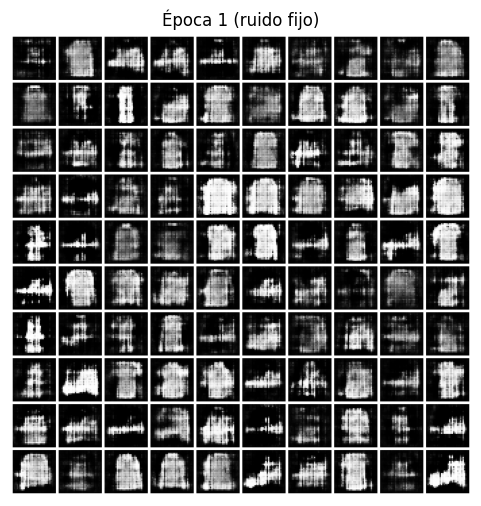

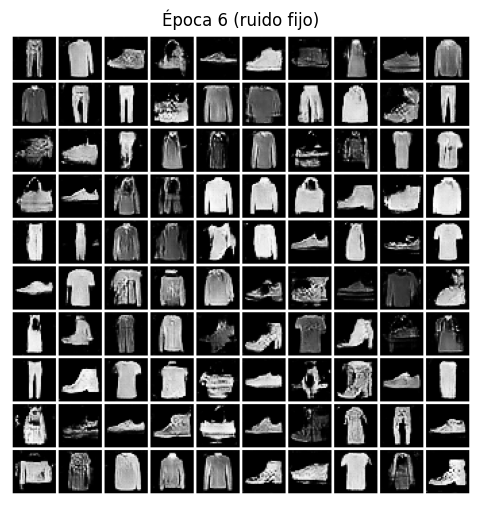

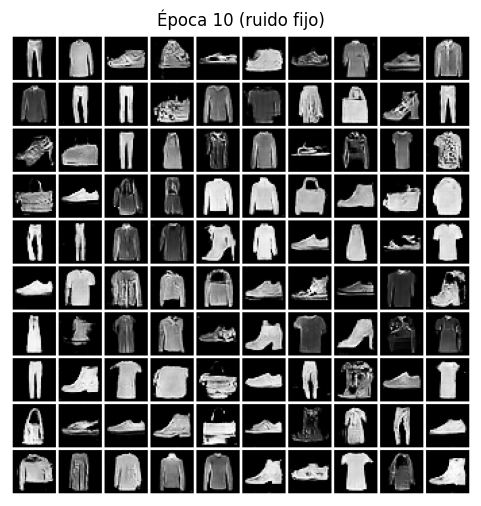

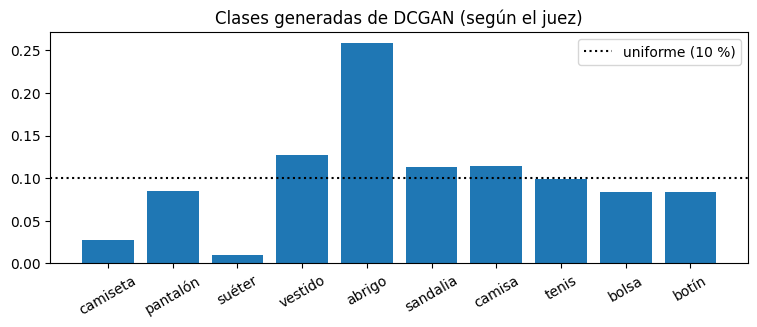

In [ ]:
ep_mostrar = sorted(set([0, len(base["rejillas"]) // 2, len(base["rejillas"]) - 1]))
for i in ep_mostrar:
    mostrar_grid(base["rejillas"][i], f"Época {i + 1} (ruido fijo)", tam=(6, 6))

# Distribución de clases según el juez en la última época
frec = base["por_epoca"].iloc[-1].frecuencias
plt.figure(figsize=(9, 3)); plt.bar(CLASES, frec); plt.axhline(0.1, c="k", ls=":", label="uniforme (10 %)")
plt.xticks(rotation=30); plt.title("Clases generadas de DCGAN (según el juez)"); plt.legend(); plt.show()

Describe la dinámica de $D(x)$ y $D(G(z))$ en tu corrida base.

¿Llegó a un régimen estable cerca de 0.5?
Ps no, no llego a los 0.5, lo mas cercano que alcanzo $D(x)$ fue 0.66 mientras que $D(G(z))$ se acerco con un 0.24

 ¿En qué época las muestras se volvieron reconocibles?
En la epoca 6

¿qué clases genera de más y cuáles de menos?
Abrigos como mas y sueter como menos

 ¿Coincide con tu inspección visual?
En parte si, porque si alcanzo a distinguir varios abrigos, pero tambien veo muchos pantalones

  ¿Por qué crees que algunas clases (p. ej., *camisa* vs. *camiseta* vs. *suéter*) son más difíciles?
  Quiero pensar, porque tienen una estructura muy parecida y el modelo, al ser parecida, lo detecta de una u otra forma, aunque no sea l clase

## Parte E Diagnóstico automático

La función de abajo aplica **reglas heurísticas** sobre el registro para señalar problemas típicos. Los umbrales son razonables para este notebook, **no universales**: tu trabajo es confirmar o refutar cada alerta con las gráficas y las imágenes.

In [ ]:
def diagnosticar(res):
    r, e, alertas = res["registro"], res["por_epoca"], []
    if "DIVERGENCIA" in res["estado"]:
        return ["Divergencia numérica: las pérdidas se volvieron NaN/inf. Típico de LR demasiado alto o sin normalización."]
    cola = r[r.it >= 0.8 * r.it.max()]                         # último 20 % del entrenamiento
    if cola.D_x.mean() > 0.85 and cola.D_Gz_antes.mean() < 0.15:
        alertas.append(f"D domina: D(x)≈{cola.D_x.mean():.2f}, D(G(z))≈{cola.D_Gz_antes.mean():.2f}. "
                       "G recibe poca información útil (riesgo de gradientes que se desvanecen).")
    if cola.D_x.mean() < 0.6 and cola.D_Gz_antes.mean() > 0.4 and cola.loss_D.mean() > 1.3:
        alertas.append("D muy débil: no distingue reales de falsas; G puede 'engañar' sin mejorar la calidad.")
    if len(e):
        ult = e.iloc[-1]
        if ult.cobertura <= 7 or ult.entropia < 1.9:
            alertas.append(f"Posible colapso de modo: cobertura {ult.cobertura}/10, entropía {ult.entropia:.2f} (máx 2.30).")
        if len(e) >= 4 and e.fid_dominio.iloc[-1] > 1.3 * e.fid_dominio.min():
            alertas.append(f"Degradación tardía: el FID de dominio subió de {e.fid_dominio.min():.1f} (mejor) a {e.fid_dominio.iloc[-1]:.1f}.")
        if ult.confianza < 0.6:
            alertas.append(f" Calidad baja: el juez solo tiene {ult.confianza:.2f} de confianza promedio (muestras ambiguas).")
    osc = cola.loss_G.rolling(100).mean().std() / (cola.loss_G.mean() + 1e-9)
    if osc > 0.25:
        alertas.append(f"Oscilación: la pérdida de G varía mucho entre ventanas (coef. de variación {osc:.2f}).")
    return alertas or ["Sin alertas"]

for a in diagnosticar(base): print(a)

Sin alertas


## Parte F Ablación
Define Ablación:  es un método de experimentación en el que eliminas, desactivas o modificas una parte específica de tu modelo (como una capa, una función de activación, una conexión o un tipo de preprocesamiento de datos) para observar cómo afecta al rendimiento final

Cada configuración cambia **una sola cosa** respecto a la base y compara. Escribe tu **hipótesis antes** de ejecutar. Selecciona un equipo y responde su pregunta

| Equipo | Variante | Cambio en `CFG` | Pregunta que responde |
|---|---|---|---|
| 1 | Sin BatchNorm | `bn=False` | ¿Qué tanto depende la estabilidad de BN? |
| 2 | Sin inicialización DCGAN | `init_dcgan=False` | ¿Importa N(0, 0.02) frente a la inicialización por defecto de PyTorch? |
| 3 | Sin *label smoothing* | `suavizado=1.0` | ¿D se vuelve demasiado confiado? |
| 4 | LR alto | `lr_G=2e-3, lr_D=2e-3` | ¿Aparece divergencia u oscilación? |
| 5 | D más fuerte | `pasos_D=5` | ¿D domina y G deja de aprender? |
| 6 | Momento de Adam | `beta1=0.9` | ¿Por qué el artículo usa 0.5? |
| 7 | Ruido de instancia | `ruido_instancia=0.1` | ¿Ayuda a estabilizar o solo emborrona? |
| 8 | Ruido latente mínimo | `nz=2` | ¿Un espacio latente pequeño limita la diversidad? |
| 9 | (CIFAR-10) | `dataset="CIFAR10"` en base y variante | ¿Qué cambia con color y fondos complejos? CReo que no llegue a entender bien la pregunta, pero a lo que me dijo en clase, Tiene mejor FID y mejor confianza y entropia del juez |

[cifar_variante] ép  1/10  loss_D 0.575  loss_G 3.587  D(x) 0.79  D(G(z)) 0.11→0.06  | cobertura 4/10  entropía 0.98  confianza 0.68  FID-d 16.5  (25 s)
[cifar_variante] ép  2/10  loss_D 0.700  loss_G 2.565  D(x) 0.73  D(G(z)) 0.16→0.13  | cobertura 8/10  entropía 1.67  confianza 0.71  FID-d 4.9  (51 s)
[cifar_variante] ép  3/10  loss_D 0.803  loss_G 2.155  D(x) 0.69  D(G(z)) 0.21→0.17  | cobertura 8/10  entropía 1.88  confianza 0.72  FID-d 2.6  (77 s)
[cifar_variante] ép  4/10  loss_D 0.826  loss_G 2.003  D(x) 0.68  D(G(z)) 0.22→0.19  | cobertura 8/10  entropía 2.02  confianza 0.73  FID-d 1.9  (102 s)
[cifar_variante] ép  5/10  loss_D 0.847  loss_G 1.925  D(x) 0.67  D(G(z)) 0.23→0.20  | cobertura 8/10  entropía 2.01  confianza 0.75  FID-d 1.4  (128 s)
[cifar_variante] ép  6/10  loss_D 0.852  loss_G 1.897  D(x) 0.67  D(G(z)) 0.23→0.20  | cobertura 9/10  entropía 2.02  confianza 0.76  FID-d 1.1  (153 s)
[cifar_variante] ép  7/10  loss_D 0.856  loss_G 1.894  D(x) 0.67  D(G(z)) 0.23→0.21 

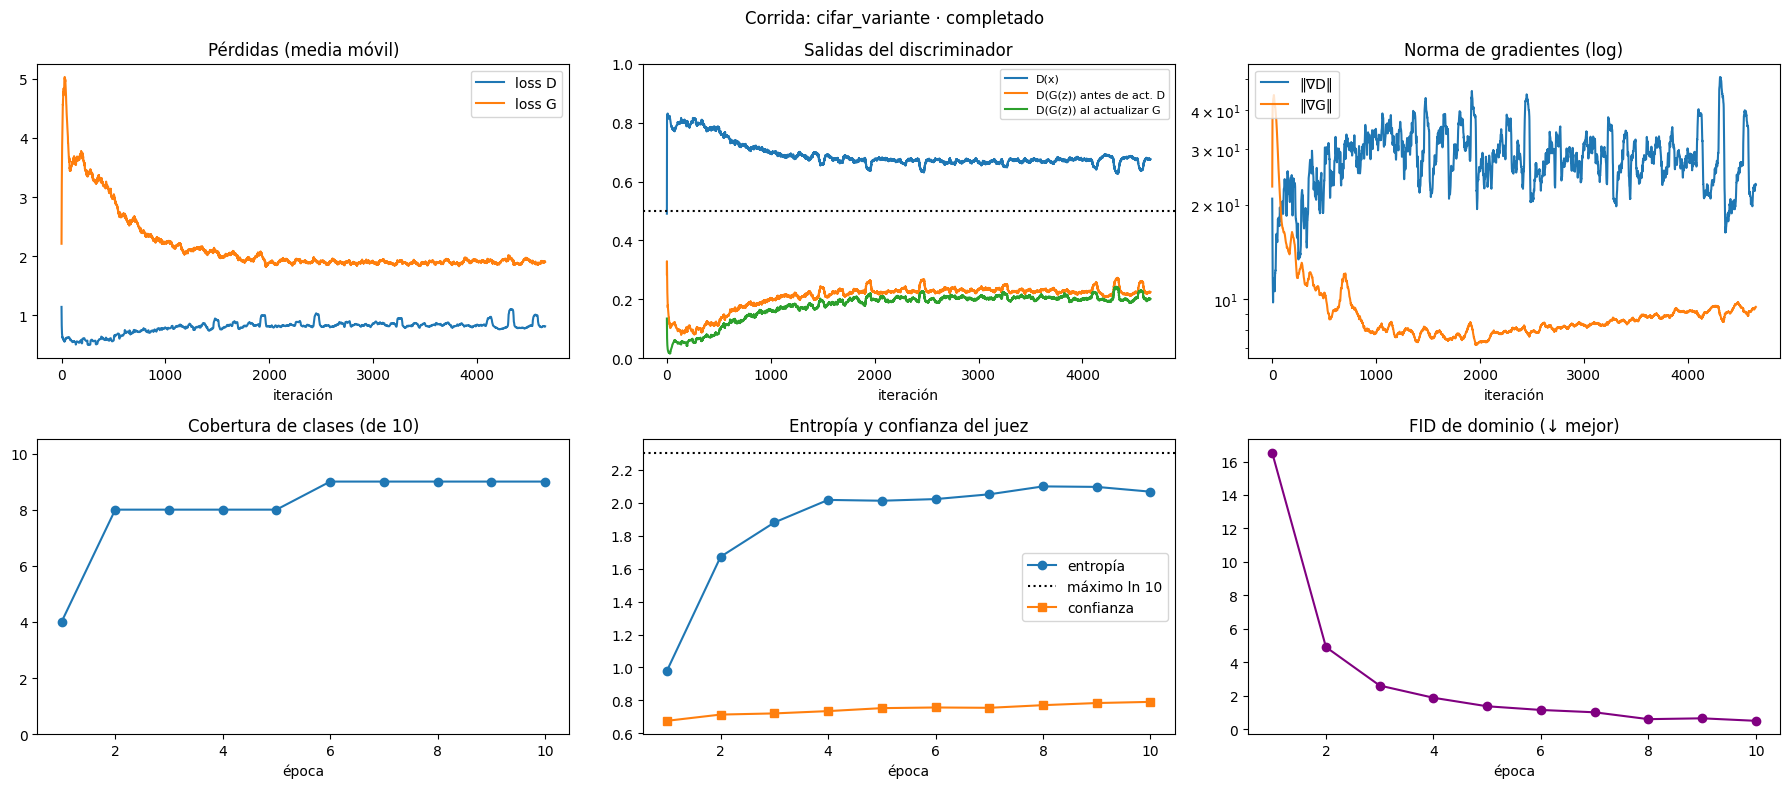

Sin alertas


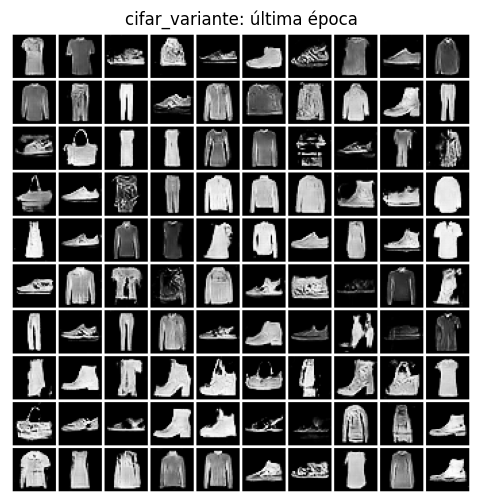

In [ ]:
#Ejecutar variantes y comparar
EQUIPO = 9          #
VARIANTES = {
    1: dict(nombre="sin_BN", bn=False),
    2: dict(nombre="sin_init", init_dcgan=False),
    3: dict(nombre="sin_suavizado", suavizado=1.0),
    4: dict(nombre="lr_alto", lr_G=2e-3, lr_D=2e-3),
    5: dict(nombre="D_5pasos", pasos_D=5),
    6: dict(nombre="beta1_0.9", beta1=0.9),
    7: dict(nombre="ruido_instancia", ruido_instancia=0.1),
    8: dict(nombre="nz_2", nz=2),
    9: dict(nombre="cifar_variante"),     # 9 decide su variante tras correr la base en CIFAR-10
}

cfg_var = {**CFG_BASE, **VARIANTES[EQUIPO]}
variante = entrenar_dcgan(cfg_var)
graficar_corrida(variante)
for a in diagnosticar(variante): print(a)
mostrar_grid(variante["rejillas"][-1] if variante["rejillas"] else torch.zeros(1, CANALES, 32, 32),
             f"{cfg_var['nombre']}: última época", tam=(6, 6))

,corrida,estado,segundos,cobertura,entropía,confianza,FID-d final,FID-d mejor,D(x) final,D(G(z)) final,alertas
0,base,completado,247.7,9,2.102,0.796,0.54,0.54,0.670,0.230,Sin alertas
1,cifar_variante,completado,255.3,9,2.067,0.791,0.49,0.49,0.672,0.228,Sin alertas


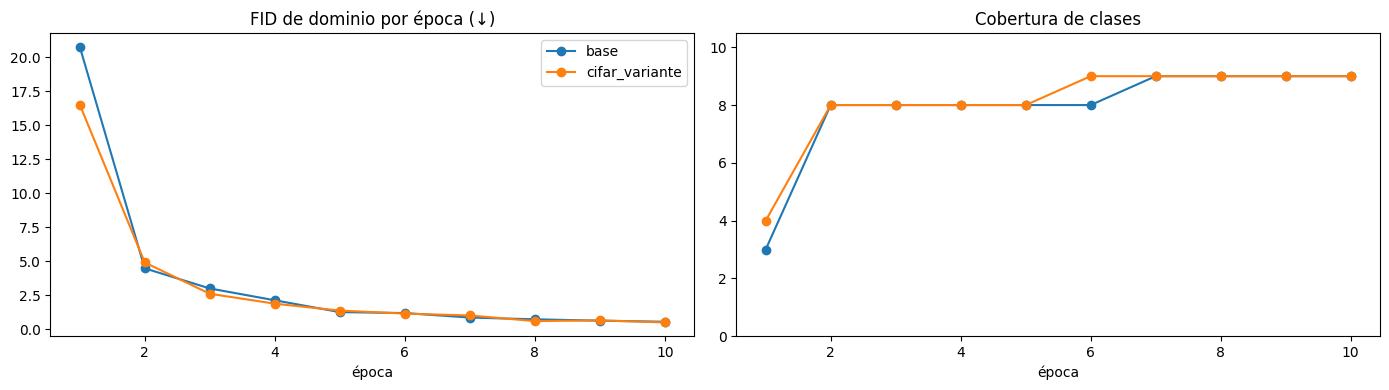

In [ ]:
def resumen(res):
    e = res["por_epoca"]; r = res["registro"]; cola = r[r.it >= 0.8 * r.it.max()]
    ult = e.iloc[-1] if len(e) else {}
    return {"corrida": res["cfg"]["nombre"], "estado": res["estado"], "segundos": res["segundos"],
            "cobertura": ult.get("cobertura"), "entropía": ult.get("entropia"), "confianza": ult.get("confianza"),
            "FID-d final": ult.get("fid_dominio"), "FID-d mejor": e.fid_dominio.min() if len(e) else None,
            "D(x) final": round(cola.D_x.mean(), 3), "D(G(z)) final": round(cola.D_Gz_antes.mean(), 3),
            "alertas": " | ".join(diagnosticar(res))}

tabla_ablacion = pd.DataFrame([resumen(base), resumen(variante)])
display(tabla_ablacion)
tabla_ablacion.to_csv(f"ablacion_equipo{EQUIPO}.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for res in [base, variante]:
    ax[0].plot(res["por_epoca"].epoca, res["por_epoca"].fid_dominio, "o-", label=res["cfg"]["nombre"])
    ax[1].plot(res["por_epoca"].epoca, res["por_epoca"].cobertura, "o-", label=res["cfg"]["nombre"])
ax[0].set(title="FID de dominio por época (↓)", xlabel="época"); ax[1].set(title="Cobertura de clases", xlabel="época", ylim=(0, 10.5))
ax[0].legend(); plt.tight_layout(); plt.savefig(f"ablacion_equipo{EQUIPO}.png", dpi=110); plt.show()

Como impacto la ablacion?
Ps la verdad estuvieron muy parejos, el cifar dio buen FID a la ablacion base

 ¿qué estrategias de estabilización fueron **imprescindibles** y cuáles **marginales** en este problema? Ps que ambos van muy iguales, van "alapar"

## Parte G Explorar el espacio latente

Si G aprendió una representación útil, moverse **suavemente** en $z$ debe producir cambios **suaves** en la imagen. Interpolamos con *slerp* (interpolación esférica), recomendada para ruido gaussiano en alta dimensión.

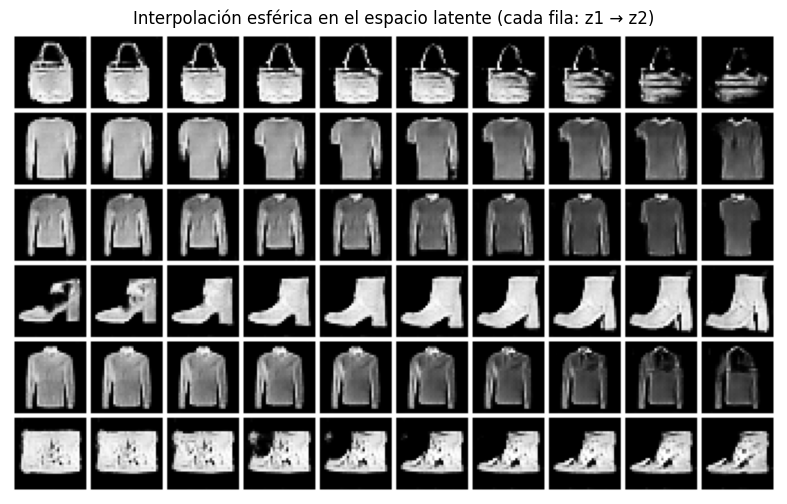

Generador(
  (red): Sequential(
    (0): ConvTranspose2d(100, 256, kernel_size=(4, 4), stride=(1, 1), bias=False)
    (1): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (4): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (7): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (8): ReLU(inplace=True)
    (9): ConvTranspose2d(64, 1, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (10): Tanh()
  )
)

In [ ]:
def slerp(z1, z2, t):
    omega = torch.acos(((z1 / z1.norm()) * (z2 / z2.norm())).sum().clamp(-1, 1))
    return (torch.sin((1 - t) * omega) * z1 + torch.sin(t * omega) * z2) / torch.sin(omega)

G = base["G"].eval(); fijar_semilla(7)
filas = []
for _ in range(6):
    z1, z2 = torch.randn(CFG_BASE["nz"], device=DEVICE), torch.randn(CFG_BASE["nz"], device=DEVICE)
    filas.append(torch.stack([slerp(z1, z2, t) for t in torch.linspace(0, 1, 10)]))
with torch.no_grad():
    imgs = G(torch.cat(filas))
mostrar_grid(imgs, "Interpolación esférica en el espacio latente (cada fila: z1 → z2)", nrow=10, tam=(10, 6))
G.train()

¿Las transiciones son suaves o hay "saltos" de clase?
almenos lo que yo veo, si veo que las transiciones sean suaves

¿Qué te dice eso sobre el espacio latente que aprendió G?
MUy bien la verdad, aprendio bien el modelo

In [ ]:
from PIL import Image as PILImage
def guardar_gif(res, ruta):
    cuadros = []
    for g in res["rejillas"]:
        r = make_grid(g, nrow=10, normalize=True, value_range=(-1, 1), pad_value=1)
        cuadros.append(PILImage.fromarray((r.permute(1, 2, 0).numpy() * 255).astype("uint8")))
    if cuadros: cuadros[0].save(ruta, save_all=True, append_images=cuadros[1:], duration=600, loop=0)

for res in [base, variante]:
    n = res["cfg"]["nombre"]
    torch.save({"G": res["G"].state_dict(), "cfg": res["cfg"]}, f"G_dcgan_{n}.pt")
    res["registro"].to_csv(f"registro_{n}.csv", index=False)
    res["por_epoca"].drop(columns="frecuencias").to_csv(f"metricas_{n}.csv", index=False)
    guardar_gif(res, f"progreso_{n}.gif")
print(sorted(f for f in os.listdir(".") if f.endswith((".pt", ".csv", ".gif", ".png"))))
# from google.colab import files; files.download("G_dcgan_base.pt"); files.download(JUEZ_RUTA)

['G_dcgan_base.pt', 'G_dcgan_cifar_variante.pt', 'ablacion_equipo9.csv', 'ablacion_equipo9.png', 'curvas_base.png', 'curvas_cifar_variante.png', 'juez_FashionMNIST.pt', 'metricas_base.csv', 'metricas_cifar_variante.csv', 'progreso_base.gif', 'progreso_cifar_variante.gif', 'registro_base.csv', 'registro_cifar_variante.csv']
